# The tagged window — what is in `annotatedCells/`, and how it relates to the HALO reference

`SLIDE-0235/phenotyping/original_delivery/window_R1/` (formerly `annotatedCells/`) holds five CSVs from the annotation tool, all on **one 1024 × 1024 px window of SLIDE-0235**
(level 0, top-left (8192, 3072), 333 µm square). Each file is one tagging session: the tool's own cell polygons over the whole
window, a phenotype tag on the cells the biologist accepted, and *untagged = negative* for that phenotype. The intensity
columns are ignored throughout — every intensity below is measured by us on the stored nine-marker stack with the dataset's
normalization. This notebook only looks; it changes nothing.

| section | question |
|---|---|
| 1 | where the window sits on the slide and in HALO region 1 |
| 2 | what the tissue looks like there — the segmenter view and the gate markers |
| 3 | the tool's cells against HALO's: outlines, centroid offsets, one-to-one matches |
| 4 | the three segmentations behind the five files |
| 5 | the tags: each tag set over its own marker, and the marker intensity of tagged vs untagged cells |

In [1]:
%load_ext autoreload
%autoreload 2
import os, re
from pathlib import Path
import cv2, numpy as np, pandas as pd, tifffile
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from shapely import wkt

from mxdata import DEFAULT_DATASET, ingest, load_config, load_regions
from mxdata.data.composite import render_channels, scaled
from mxdata.io import Box
from mxdata.pipeline.stats import NormStats
from mxseg.analysis import load_panel

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = Path(os.environ.get("MXDATA_DATASET", DEFAULT_DATASET))
from mxdata.phenotyping import phenotyping_dir
ANNOT = Path(os.environ.get("MXDATA_ANNOTATED", phenotyping_dir("SLIDE-0235", DATASET.parent) / "original_delivery" / "window_R1"))   # the tool window, unified store

# ---- edit here ---------------------------------------------------------------------------------------------------------
SLIDE = "SLIDE-0235"
STEM = "SLIDE-0235_Final_x8192_y3072_l0"                  # the window: <slide>_Final_x<x0>_y<y0>_l<level>
SIZE = 1024
SESSIONS = {                                              # phenotype (configs/panel.yaml name) -> (file suffix, tags that mean it)
    "Epithelial":  ("_PanCK.csv",    {"PanCK"}),
    "T cell":      (".Tcell.csv",    {"Tcell", "Tcqell"}),        # "Tcqell" = one typo of Tcell
    "CD4+ T cell": (".CD4+Tcell.csv", {"CD4+Tcell"}),
    "CD8+ T cell": (".CD8+Tcell.csv", {"CD8+Tcell"}),
}
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
SPLIT_COLOR = {"train": "#FFFFFF", "val": "#FFB000", "test": "#35D6FF"}
HALO_C, TOOL_C, WIN_C = "#35D6FF", "#FFB000", "#FF2ED1"
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def display(x, gain=1.0, gamma=0.8):
    return np.clip(x * gain, 0, 1) ** gamma

def hexrgb(h):
    return [int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)]

def tinted(x, color, gain=1.4):
    """A single marker as its panel color on black."""
    return np.clip(display(x, gain)[..., None] * np.array(hexrgb(color))[None, None], 0, 1)

def outlines(ax, rings, color, lw=0.45, alpha=0.9):
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings], colors=color, linewidths=lw, alpha=alpha))

cfg = load_config(REPO / "configs" / "dataset.yaml")
panelcfg = load_panel(REPO / "configs" / "panel.yaml")
GATE = {p.name: p.marker for p in panelcfg.phenotypes}
MARKERS = list(cfg.markers)
stats = NormStats.load(DATASET / SLIDE / "stats.json")
NORMS = {m: (stats.lo[m], stats.hi[m]) for m in MARKERS}
paths, mx, _ = ingest(SLIDE, None)
PX_UM = float(mx.pixel_size_um or 0.325)
regions = {r.region_id: r for r in load_regions(paths, None, cfg.min_area_px)}
pt = pd.read_csv(DATASET / "patches.csv", usecols=["slide", "kind", "region_id", "split", "kept"])
split_of = pt[(pt.slide == SLIDE) & (pt.kind == "labeled") & pt.kept].groupby("region_id").split.first().to_dict()

m = re.search(r"_x(\d+)_y(\d+)_l(\d+)$", STEM)
X0, Y0, LEVEL = int(m.group(1)), int(m.group(2)), int(m.group(3))
W = Box(X0, Y0, X0 + SIZE, Y0 + SIZE)
stack = mx.read_region(W, MARKERS, LEVEL)                                          # (9, 1024, 1024) uint16, the stored markers, live
S = {mk: scaled(stack[i], *NORMS[mk]) for i, mk in enumerate(MARKERS)}            # each marker in the dataset's [0, 1]

def load_session(suffix):
    d = pd.read_csv(ANNOT / f"{STEM}{suffix}")
    d["ring"] = [np.asarray(wkt.loads(p).exterior.coords, float)[:, :2] - [X0, Y0] for p in d.polygon]
    lab = np.zeros((SIZE, SIZE), np.int32)
    for cid, ring in zip(d.cell_id, d.ring):
        cv2.fillPoly(lab, [np.round(ring).astype(np.int32)], int(cid))
    return d, lab
sessions = {name: load_session(suf) for name, (suf, _) in SESSIONS.items()}
for name, (_, tags) in SESSIONS.items():
    d = sessions[name][0]
    d["positive"] = d.cell_type.isin(tags) & (d.tag == "accepted")
base, base_lab = load_session(".csv")

# HALO's cells of the regions the window touches
touching = [rid for rid, r in regions.items() if r.box.x0 < W.x1 and r.box.x1 > W.x0 and r.box.y0 < W.y1 and r.box.y1 > W.y0]
R = regions[touching[0]]
halo_lab = R.label_map(W).astype(np.int32)
halo_rings = [np.asarray(r, float)[:, :2] - [X0, Y0] for r in R.rings if (r[:, 0].max() >= X0 and r[:, 0].min() < W.x1 and r[:, 1].max() >= Y0 and r[:, 1].min() < W.y1)]
nuc = R.nuclei
in_win = nuc[nuc.cx.between(W.x0, W.x1) & nuc.cy.between(W.y0, W.y1)]
OV = Box(max(W.x0, R.box.x0), max(W.y0, R.box.y0), min(W.x1, R.box.x1), min(W.y1, R.box.y1))
print(f"window {W.xyxy} = {SIZE * PX_UM:.0f} µm | touches HALO region(s) {touching}; R{R.region_id} box {R.box.xyxy} "
      f"({split_of.get(R.region_id, '?')} split, QC table: {R.has_qc}) | overlap {OV.xyxy} = "
      f"{100 * OV.width * OV.height / SIZE ** 2:.0f} % of the window; {len(in_win)} HALO nuclei in it")
for name, (d, _) in sessions.items():
    print(f"{name:<12} {SESSIONS[name][0]:<16} {len(d):>5} cells, {int(d.positive.sum()):>5} tagged {name}")
print(f"{'(base)':<12} {'.csv':<16} {len(base):>5} cells")

window (8192, 3072, 9216, 4096) = 333 µm | touches HALO region(s) [1]; R1 box (8073, 2896, 9562, 3828) (train split, QC table: True) | overlap (8192, 3072, 9216, 3828) = 74 % of the window; 758 HALO nuclei in it
Epithelial   _PanCK.csv        1283 cells,  1006 tagged Epithelial
T cell       .Tcell.csv        1277 cells,    40 tagged T cell
CD4+ T cell  .CD4+Tcell.csv    1277 cells,    26 tagged CD4+ T cell
CD8+ T cell  .CD8+Tcell.csv    1291 cells,    12 tagged CD8+ T cell
(base)       .csv              1291 cells


## 1. Where the window is

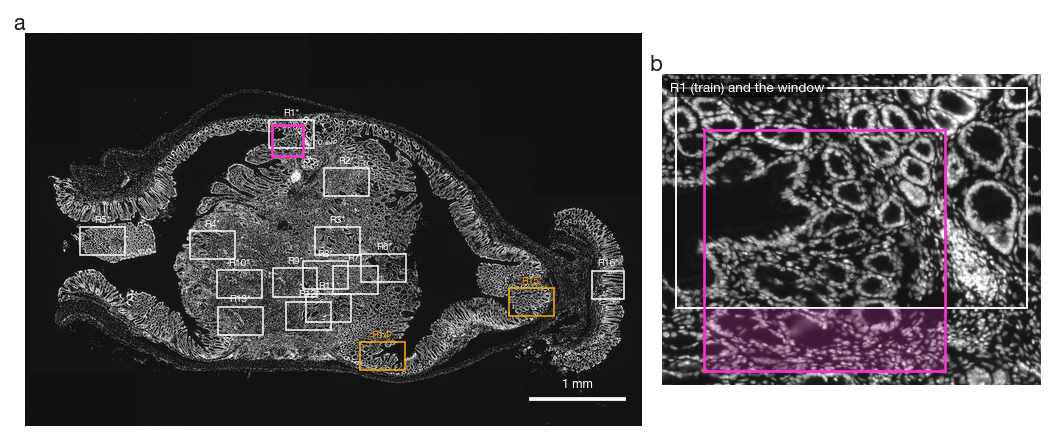

In [2]:
thumb, ds = mx.thumbnail(max_dim=2000, markers=["DAPI"])
dapi = np.clip(thumb[0].astype(np.float32) / np.percentile(thumb[0], 99.5), 0, 1) ** 0.7
H_, W_ = dapi.shape
fig = plt.figure(figsize=(7.6, 3.3))
gs = fig.add_gridspec(1, 2, width_ratios=[2.2, 1.35], wspace=0.04, left=0.005, right=0.995, top=0.95, bottom=0.02)
a = fig.add_subplot(gs[0])
a.imshow(dapi, cmap="gray", vmin=0, vmax=1, interpolation="lanczos")
for rid, r in regions.items():
    b, sp = r.box, split_of.get(rid, "train")
    a.add_patch(Rectangle((b.x0 / ds, b.y0 / ds), b.width / ds, b.height / ds, fill=False, ec=SPLIT_COLOR[sp], lw=0.8))
    a.text(b.x0 / ds + b.width / ds / 2, b.y0 / ds - 0.008 * H_, f"R{rid}{'*' if r.has_qc else ''}", color=SPLIT_COLOR[sp], fontsize=5.4, fontweight="bold", ha="center", va="bottom")
a.add_patch(Rectangle((W.x0 / ds, W.y0 / ds), SIZE / ds, SIZE / ds, fill=False, ec=WIN_C, lw=1.4))
a.set_xlim(0, W_); a.set_ylim(H_, 0); a.set_axis_off()
L = 1000 / (PX_UM * ds); a.plot([W_ * 0.97 - L, W_ * 0.97], [H_ * 0.93] * 2, color="white", lw=2); a.text(W_ * 0.97 - L / 2, H_ * 0.90, "1 mm", color="white", ha="center", fontsize=6.5)
panel(a, "a", dx=0.0, dy=1.0)
b_ = fig.add_subplot(gs[1])
pad = 60
crop = Box(min(R.box.x0, W.x0) - pad, min(R.box.y0, W.y0) - pad, max(R.box.x1, W.x1) + pad, max(R.box.y1, W.y1) + pad)
cd = mx.read_region(crop, ["DAPI"], 0)[0].astype(np.float32)
cd = np.clip(cd / np.percentile(cd, 99.5), 0, 1) ** 0.7
b_.imshow(cd, cmap="gray", vmin=0, vmax=1)
b_.add_patch(Rectangle((R.box.x0 - crop.x0, R.box.y0 - crop.y0), R.box.width, R.box.height, fill=False, ec=SPLIT_COLOR[split_of.get(R.region_id, "train")], lw=1.0))
b_.add_patch(Rectangle((W.x0 - crop.x0, W.y0 - crop.y0), SIZE, SIZE, fill=False, ec=WIN_C, lw=1.4))
b_.add_patch(Rectangle((W.x0 - crop.x0, OV.y1 - crop.y0), SIZE, W.y1 - OV.y1, fill=True, fc=WIN_C, ec="none", alpha=0.18))
b_.set_axis_off(); chip(b_, f"R{R.region_id} ({split_of.get(R.region_id, '?')}) and the window")
panel(b_, "b", dx=0.0, dy=1.0)
plt.show()

**Figure 1 — Where the window is.** (a) The slide (DAPI) with the HALO regions boxed by split (white training, amber
validation, cyan test; \* = reviewed) and the tagged window in magenta. (b) Region 1 and the window at level 0: the window
lies inside the region horizontally, but the region ends 268 rows above the window's bottom — the shaded strip is tissue
that no HALO annotation covers. Region 1 is a training region of the segmenters; since the full review of the slide it carries a QC table like every other region.

## 2. What the tissue looks like there

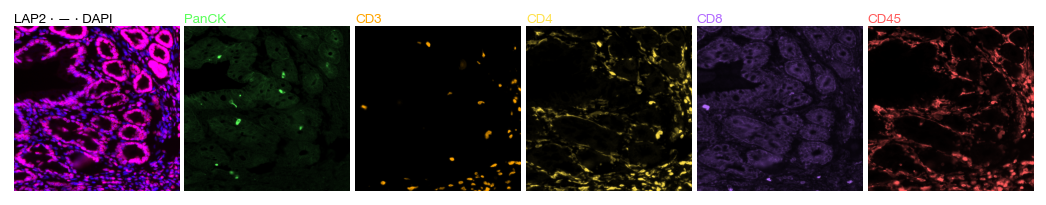

In [3]:
seg = ("LAP2", None, "DAPI")
show = ["PanCK", "CD3", "CD4", "CD8", "CD45"]
fig, axes = plt.subplots(1, 6, figsize=(7.6, 1.45))
fig.subplots_adjust(wspace=0.03, left=0.003, right=0.997, top=0.86, bottom=0.01)
axes[0].imshow(display(render_channels(stack, MARKERS, NORMS, seg), gain=1.6).transpose(1, 2, 0)); axes[0].set_title("LAP2 · — · DAPI", fontsize=7.2, pad=2)
for ax, mk in zip(axes[1:], show):
    ax.imshow(tinted(S[mk], panelcfg.colors[mk])); ax.set_title(mk, fontsize=7.2, pad=2, color=panelcfg.colors[mk])
for ax in axes:
    ax.set_axis_off()
plt.show()

**Figure 2 — The window, as stored.** The segmenter view (LAP2 red, DAPI blue) and the five phenotype markers of the panel
that the tags refer to, each scaled by the slide's stored normalization. Glandular crypts with stroma between them: CD4 and
CD45 light up the stroma, CD3 a few dozen T cells, CD8 very little — and PanCK is faint, because the crypt epithelium of this
region stains far below the regions that set the slide's normalization (section 5). The tag counts follow the morphology:
about a thousand epithelial cells, a few dozen T cells.

## 3. The tool's cells against HALO's

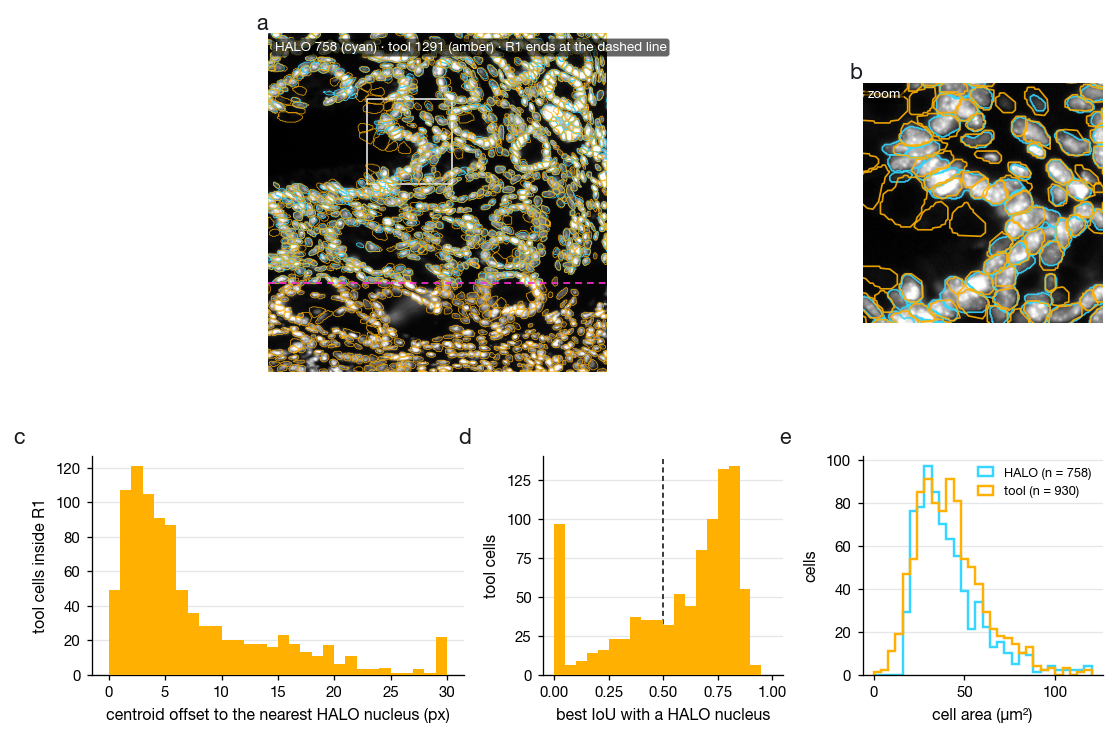

inside R1: 930 tool cells vs 758 HALO nuclei | 68 % of tool cells match a HALO nucleus at IoU ≥ 0.5, 6 % overlap none | centroid offset median 4.9 px | below R1: 361 tool cells, no HALO reference


In [4]:
d0 = base
tool_lab = base_lab
gray = display(S["DAPI"], gain=1.3)
# best-overlap match of every tool cell to a HALO nucleus (inside the overlap only, where HALO exists)
sel = tool_lab > 0
pairs, cnt = np.unique(np.stack([tool_lab[sel], halo_lab[sel]]), axis=1, return_counts=True)
area_t, area_h = np.bincount(tool_lab.ravel()), np.bincount(halo_lab.ravel())
inter = pd.DataFrame({"t": pairs[0], "h": pairs[1], "i": cnt}); inter = inter[inter.h > 0]
inter["iou"] = inter.i / (area_t[inter.t] + area_h[inter.h] - inter.i)
best = inter.sort_values("iou").groupby("t").tail(1).set_index("t").iou
d0["inside"] = d0.x.between(OV.x0, OV.x1) & d0.y.between(OV.y0, OV.y1)
d0["best_iou"] = d0.cell_id.map(best).fillna(0.0)
tree = cKDTree(nuc[["cx", "cy"]].to_numpy(float))
d0["offset"], _ = tree.query(d0[["x", "y"]].to_numpy())
ins = d0[d0.inside]

fig = plt.figure(figsize=(7.6, 5.4))
gs = fig.add_gridspec(2, 3, width_ratios=[1.55, 1, 1], height_ratios=[1.55, 1], wspace=0.28, hspace=0.3, left=0.005, right=0.99, top=0.96, bottom=0.08)
a = fig.add_subplot(gs[0, :2])
a.imshow(gray, cmap="gray", vmin=0, vmax=1)
outlines(a, halo_rings, HALO_C, lw=0.4); outlines(a, list(d0.ring), TOOL_C, lw=0.4)
a.axhline(OV.y1 - Y0, color=WIN_C, lw=0.9, ls=(0, (4, 3)))
a.set_xlim(0, SIZE); a.set_ylim(SIZE, 0); a.set_axis_off()
chip(a, f"HALO {len(in_win)} (cyan) · tool {len(d0)} (amber) · R{R.region_id} ends at the dashed line")
panel(a, "a", dx=0.0, dy=1.0)
z = Box(300, 200, 556, 456)                                                            # a 256² zoom
b_ = fig.add_subplot(gs[0, 2])
b_.imshow(gray, cmap="gray", vmin=0, vmax=1)
outlines(b_, halo_rings, HALO_C, lw=0.9); outlines(b_, list(d0.ring), TOOL_C, lw=0.9)
b_.set_xlim(z.x0, z.x1); b_.set_ylim(z.y1, z.y0); b_.set_axis_off(); chip(b_, "zoom")
a.add_patch(Rectangle((z.x0, z.y0), z.width, z.height, fill=False, ec="white", lw=0.8))
panel(b_, "b", dx=0.0, dy=1.0)
c = fig.add_subplot(gs[1, 0])
c.hist(ins.offset.clip(0, 30), bins=np.arange(0, 31, 1), color=TOOL_C, zorder=3)
c.set_xlabel("centroid offset to the nearest HALO nucleus (px)"); c.set_ylabel("tool cells inside R%d" % R.region_id); ygrid(c)
panel(c, "c", dx=-0.18)
d_ = fig.add_subplot(gs[1, 1])
d_.hist(ins.best_iou, bins=np.linspace(0, 1, 21), color=TOOL_C, zorder=3)
d_.axvline(0.5, color=INK, lw=0.9, ls=(0, (3, 2)))
d_.set_xlabel("best IoU with a HALO nucleus"); d_.set_ylabel("tool cells"); ygrid(d_)
panel(d_, "d", dx=-0.3)
e = fig.add_subplot(gs[1, 2])
areas = pd.DataFrame({"HALO": in_win.area_px.to_numpy() * PX_UM ** 2, "tool": ins.area_px.to_numpy() * PX_UM ** 2}.items())
for name, arr, col in (("HALO", in_win.area_px * PX_UM ** 2, HALO_C), ("tool", ins.area_px * PX_UM ** 2, TOOL_C)):
    e.hist(arr, bins=np.linspace(0, 120, 31), histtype="step", lw=1.3, color=col, label=f"{name} (n = {len(arr)})")
e.set_xlabel("cell area (µm²)"); e.set_ylabel("cells"); e.legend(fontsize=6.8, handlelength=1.2); ygrid(e)
panel(e, "e", dx=-0.3)
plt.show()
print(f"inside R{R.region_id}: {len(ins)} tool cells vs {len(in_win)} HALO nuclei | {100 * (ins.best_iou >= 0.5).mean():.0f} % of tool cells match a HALO "
      f"nucleus at IoU ≥ 0.5, {100 * (ins.best_iou == 0).mean():.0f} % overlap none | centroid offset median {ins.offset.median():.1f} px "
      f"| below R{R.region_id}: {int((~d0.inside).sum())} tool cells, no HALO reference")

**Figure 3 — Two segmentations of the same cells.** (a) DAPI with HALO's nuclei (cyan) and the tool's cells of the base
file (amber); below the dashed line there is no HALO annotation. (b) A 256 px zoom: the outlines follow the same nuclei but
are drawn differently, and the tool splits or adds objects where HALO has one. (c–d) For the tool cells inside region 1, the
distance to the nearest HALO centroid and the best IoU with a HALO nucleus: two thirds of the cells match one HALO nucleus
at IoU ≥ 0.5, the rest are offset, split or unmatched. (e) Both segmentations describe DAPI-anchored objects of the same size. The conclusion for the
benchmark: these polygons locate the tagged cells, they are not a second segmentation reference.

## 4. The three segmentations behind the five files

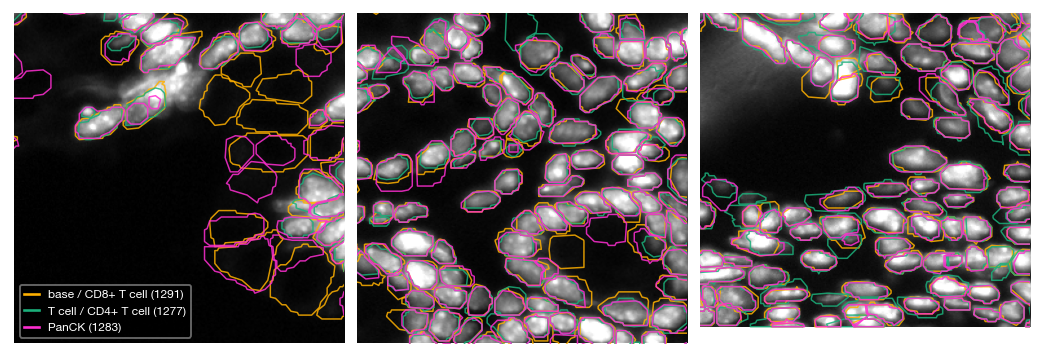

T cell / CD4+ T cell: 76 % of its cells sit within 3 px of a base-file cell
PanCK: 81 % of its cells sit within 3 px of a base-file cell


In [5]:
groups = {"base / CD8+ T cell": base, "T cell / CD4+ T cell": sessions["T cell"][0], "PanCK": sessions["Epithelial"][0]}
cols = ["#FFB000", "#1BAF7A", "#FF2ED1"]
fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.75))
fig.subplots_adjust(wspace=0.03, left=0.003, right=0.997, top=0.9, bottom=0.01)
zooms = [Box(120, 120, 376, 376), Box(560, 380, 816, 636), Box(400, 780, 656, 1036)]
for ax, zb in zip(axes, zooms):
    ax.imshow(gray, cmap="gray", vmin=0, vmax=1)
    for (name, d), col in zip(groups.items(), cols):
        outlines(ax, list(d.ring), col, lw=0.8, alpha=0.85)
    ax.set_xlim(zb.x0, zb.x1); ax.set_ylim(zb.y1, zb.y0); ax.set_axis_off()
for (name, d), col in zip(groups.items(), cols):
    axes[0].plot([], [], color=col, lw=1.4, label=f"{name} ({len(d)})")
axes[0].legend(loc="lower left", fontsize=6.4, handlelength=1.2, labelcolor="white", facecolor="black", framealpha=0.5, frameon=True)
plt.show()
t0 = cKDTree(base[["x", "y"]].to_numpy())
for name, d in list(groups.items())[1:]:
    dist, _ = t0.query(d[["x", "y"]].to_numpy())
    print(f"{name}: {100 * (dist < 3).mean():.0f} % of its cells sit within 3 px of a base-file cell")

**Figure 4 — Not one segmentation but three.** Three zooms with the outlines of the three distinct cell sets found across
the five files: the base and CD8 files share one, the T cell and CD4 files another, the PanCK file a third. Most cells
coincide, a fifth to a quarter do not, so a tag can only be transferred between sessions by matching cells, never by id.

## 5. The tags

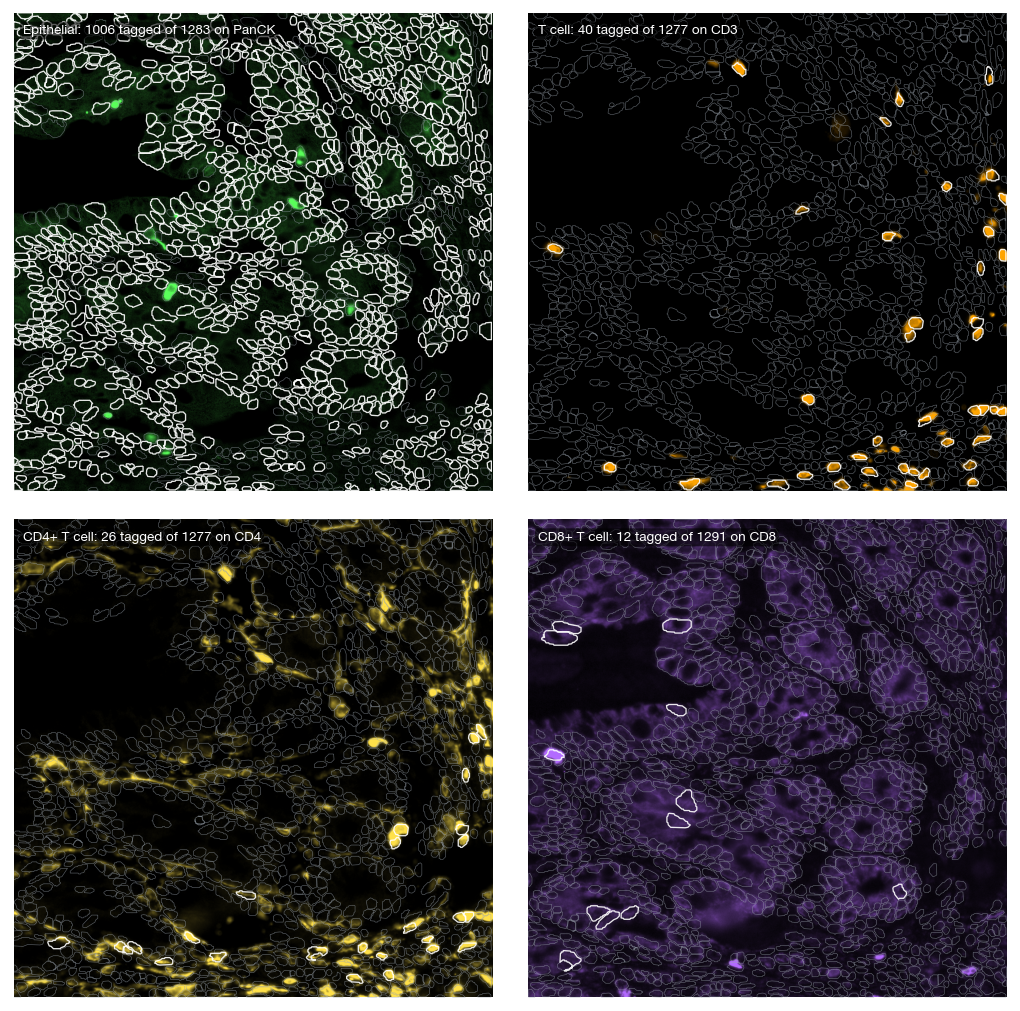

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(7.6, 7.6))
fig.subplots_adjust(wspace=0.02, hspace=0.06, left=0.003, right=0.997, top=0.97, bottom=0.01)
for ax, (name, (d, lab)) in zip(axes.ravel(), sessions.items()):
    mk, col = GATE[name], panelcfg.colors[GATE[name]]
    ax.imshow(tinted(S[mk], col, gain=1.6))
    outlines(ax, list(d.ring[~d.positive]), "#9AA3AD", lw=0.35, alpha=0.55)
    outlines(ax, list(d.ring[d.positive]), "white", lw=0.7)
    ax.set_axis_off(); chip(ax, f"{name}: {int(d.positive.sum())} tagged of {len(d)} on {mk}")
plt.show()

**Figure 5 — Each tag set over its own gate marker.** The window's gate marker in its panel color (PanCK for Epithelial,
CD3 for T cell, CD4 and CD8 for the subsets), with the tagged cells outlined in white and the untagged — the negatives of
that session — in gray. This is the check that matters: a tag should sit on a bright cell, and bright cells should be tagged.

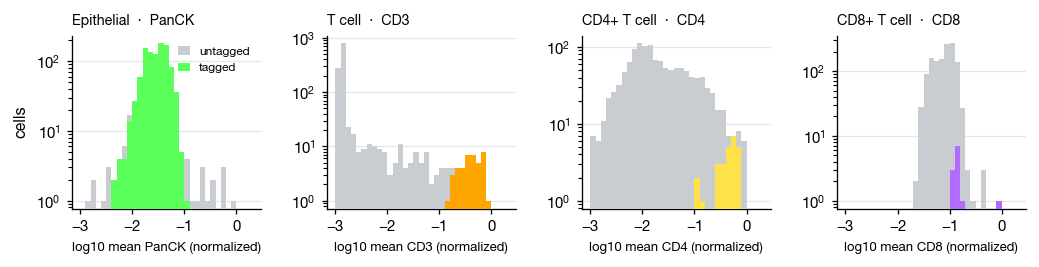

  phenotype marker  tagged  median tagged  median untagged  % tagged above the untagged 95th pct
 Epithelial  PanCK    1006          0.029            0.016                                 0.000
     T cell    CD3      40          0.401            0.000                               100.000
CD4+ T cell    CD4      26          0.453            0.015                                88.462
CD8+ T cell    CD8      12          0.134            0.083                                41.667
PanCK 99th percentile — this window: 1383, held-out regions: R14 1157, R15 5835 | normalization window 0-12573


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(7.6, 2.1))
fig.subplots_adjust(wspace=0.35, left=0.06, right=0.99, top=0.85, bottom=0.24)
summary = []
for ax, (name, (d, lab)) in zip(axes, sessions.items()):
    mk, col = GATE[name], panelcfg.colors[GATE[name]]
    ids = d.cell_id.to_numpy()
    mean = ndi.mean(S[mk], labels=lab, index=ids)                                     # our measurement: mean of the normalized marker inside each polygon
    d[f"{mk}_mean"] = mean
    v = np.log10(np.asarray(mean) + 1e-3)
    bins = np.linspace(-3, 0.3, 34)
    ax.hist(v[~d.positive], bins=bins, color="#C9CDD2", label="untagged", zorder=3)
    ax.hist(v[d.positive], bins=bins, color=col, label="tagged", zorder=4)
    ax.set_title(f"{name}  ·  {mk}", fontsize=7.6); ax.set_xlabel(f"log10 mean {mk} (normalized)", fontsize=7); ax.set_yscale("log"); ygrid(ax)
    if ax is axes[0]:
        ax.set_ylabel("cells")
        ax.legend(fontsize=6.4, handlelength=1.0)
    pos, neg = np.asarray(mean)[d.positive.to_numpy()], np.asarray(mean)[~d.positive.to_numpy()]
    summary.append((name, mk, len(pos), np.median(pos), np.median(neg), 100 * (pos > np.percentile(neg, 95)).mean() if len(pos) else np.nan))
plt.show()
print(pd.DataFrame(summary, columns=["phenotype", "marker", "tagged", "median tagged", "median untagged", "% tagged above the untagged 95th pct"]).round(3).to_string(index=False))
tests = sorted(rid for rid, sp in split_of.items() if sp == "test") or sorted(rid for rid, sp in split_of.items() if sp == "val")   # the slide's held-out regions
p99 = {f"R{rid}": np.percentile(mx.read_region(regions[rid].box, ["PanCK"], 0)[0], 99) for rid in tests}
print(f"PanCK 99th percentile — this window: {np.percentile(stack[MARKERS.index('PanCK')], 99):.0f}, held-out regions: "
      + ", ".join(f"{k} {v:.0f}" for k, v in p99.items()) + f" | normalization window {NORMS['PanCK'][0]:.0f}-{NORMS['PanCK'][1]:.0f}")

**Figure 6 — Is the tag visible in our data?** For each session, the mean of the gate marker inside every polygon, measured
on the stored nine-marker stack with the dataset's normalization, tagged cells in color over the untagged rest (log counts).
CD3 and CD4 separate the tagged cells cleanly, CD8 only partly, PanCK not at all: the epithelium of this window stains at
about a tenth of the slide's PanCK range (its 99th percentile against the normalization window and the slide's held-out validation regions,
printed above), so a slide-level PanCK gate cannot recover the Epithelial tags here — they follow the crypt morphology.
For phenotyping this window tests a gate's robustness to stain variation; it is not a calibration set for PanCK.